# 6. Wichtigkeit von Knoten & Knotengruppen

Wir untersuchen, welche Athleten und Gruppen im **Arbeitsnetz mit `weight >= 2`**
zentral sind. Grundlage ist ausschliesslich die gespeicherte Athletenprojektion
aus Kapitel 3; wir modellieren das Netzwerk nicht neu und erheben keine neuen Daten.
Die tatsächlichen Louvain-Zuordnungen werden aus dem Export von Kapitel 5 gelesen.

Eine Kante bedeutet mindestens zwei gemeinsame Veranstaltungstage in den
gespeicherten Bestleistungen. Zentralität beschreibt hier diese beobachtete
Struktur, weder persönliche Bekanntschaft noch eine vollständige Wettkampfbiografie.
Die Hilfsfunktionen in `centrality_utils.py` enthalten Cache, Multi-Source-BFS und
den monadischen Permutationstest; kleine Referenzgraphen prüfen ihre Definitionen.

In [1]:
from pathlib import Path
import hashlib
import json
import sys

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
import networkx as nx
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
from scipy.sparse.linalg import eigsh
from scipy.stats import spearmanr
from IPython.display import Markdown, display

PROJECT_ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / 'Notebooks'))
from centrality_utils import (
    load_work_graph, graph_metadata, expensive_centrality,
    group_centrality, monadic_permutation_tests, load_analysis_result,
)

NETWORK_DIR = PROJECT_ROOT / 'data/processed/networks'
RESULT_DIR = PROJECT_ROOT / 'data/processed/centrality'
CACHE_DIR = RESULT_DIR / 'cache'
REPORT_DIR = PROJECT_ROOT / 'Report/graphics'
WORK_THRESHOLD = 2
EXPECTED_GC_SIZE = 12_709
RECOMPUTE_EXPENSIVE = False
# Nur das gewählte fehlende Mass neu berechnen; Standardlauf lädt beide Caches.
EXPENSIVE_MEASURES = ('betweenness',)
N_PERMUTATIONS, SEED, ALPHA = 9_999, 42, 0.05
COLOR, MUTED = '#367da2', '#a3a29d'
COMMUNITY_COLORS = {'C1': '#8cb900', 'C2': '#eb6834', 'C3': '#1baf7a', 'C4': '#c13a8a'}
LABELS = {'degree_centrality': 'Degree', 'weighted_degree': 'Weighted Degree',
          'harmonic': 'Harmonic Closeness', 'betweenness': 'Betweenness',
          'eigenvector': 'Eigenvector'}
REPORT_RC = {'font.size': 8, 'axes.titlesize': 9, 'axes.labelsize': 8,
             'xtick.labelsize': 7, 'ytick.labelsize': 7, 'pdf.fonttype': 42}
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e5e4e0', 'grid.linewidth': 0.8,
    'axes.axisbelow': True, 'axes.edgecolor': '#52514e',
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
})
for directory in [RESULT_DIR, CACHE_DIR, REPORT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

def pretty_name(value):
    last, separator, first = value.partition(', ')
    return f'{first} {last.title()}' if separator else value

def digest(path):
    with Path(path).open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()

## 6.1 Graphbasis und gespeicherte Communities

Zuerst bleiben **alle Knoten** erhalten, einschliesslich der durch den Kantenfilter
isolierten Athleten. Die Giant Component wird erst danach bestimmt und mit der
erwarteten Grösse 12'709 verglichen. Der Graph ist einfach, ungerichtet und ohne
Selbstschleifen; die Gewichte zählen positive ganze Veranstaltungstage.

Der Export von Kapitel 5 besitzt keine Graph-Metadaten. Wir prüfen deshalb seine
eindeutigen Knotenkennungen, vollständige Abdeckung und die dokumentierten Grössen
von C1–C4. Sein SHA-256 wird für die Nachvollziehbarkeit gespeichert. Die Partition
wird unverändert übernommen; ihre Entstehung auf genau diesem Kantenstand lässt
sich allein aus dem Export nicht nachträglich beweisen. Falls die Datei fehlt,
entfallen Community-Aussagen, ohne Gruppen zu erfinden.

In [2]:
G_work, source_sha256 = load_work_graph(NETWORK_DIR / 'athletes.gexf', WORK_THRESHOLD)
components = list(nx.connected_components(G_work))
giant_nodes = max(components, key=len)
G_gc = G_work.subgraph(sorted(giant_nodes)).copy()
assert len(G_gc) == EXPECTED_GC_SIZE, 'GC weicht vom Projektstand ab: Datenstand prüfen.'
athletes = pd.DataFrame.from_dict(dict(G_work.nodes(data=True)), orient='index').sort_index()
athletes.index.name = 'node'
assert athletes['athlete_id'].is_unique
assert (athletes.index == 'athlete_' + athletes['athlete_id'].astype(str)).all()
athletes['birth_year'] = pd.to_numeric(athletes['birth_year'], errors='coerce').astype('Int64')
athletes['in_gc'] = athletes.index.isin(giant_nodes)
graph_summary = {
    'Knoten Arbeitsnetz': len(G_work), 'Kanten Arbeitsnetz': G_work.number_of_edges(),
    'Isolierte Knoten': nx.number_of_isolates(G_work), 'Komponenten': len(components),
    'Knoten Giant Component': len(G_gc), 'Kanten Giant Component': G_gc.number_of_edges(),
    'Anteil Giant Component': len(G_gc) / len(G_work),
}
display(pd.Series(graph_summary, name='Wert').to_frame())

community_path = NETWORK_DIR / 'athlete_communities.parquet'
community_sha256 = None
if community_path.exists():
    assignments = pd.read_parquet(community_path)
    assert assignments['node'].is_unique and assignments['louvain'].notna().all()
    assert set(assignments['node']) == set(G_work), 'Community-Export passt nicht zu den Knoten.'
    communities = assignments.set_index('node')['louvain'].reindex(athletes.index)
    expected_sizes = pd.Series({'C1': 2064, 'C2': 1881, 'C3': 1304, 'C4': 1175})
    assert communities.value_counts().reindex(expected_sizes.index).eq(expected_sizes).all()
    community_sha256 = digest(community_path)
    athletes['community'] = communities
    display(communities.value_counts().reindex(COMMUNITY_COLORS).to_frame('Athleten'))
else:
    athletes['community'] = pd.Series(pd.NA, index=athletes.index, dtype='string')
    print('Community-Export fehlt: keine neuen Zuordnungen; Community-Analysen entfallen.')

,Wert
Knoten Arbeitsnetz,13156.000000
Kanten Arbeitsnetz,357219.000000
Isolierte Knoten,413.000000
Komponenten,428.000000
Knoten Giant Component,12709.000000
Kanten Giant Component,357190.000000
Anteil Giant Component,0.966023


,Athleten
louvain,
C1,2064
C2,1881
C3,1304
C4,1175


## 6.2 Aktor-Zentralitäten: Definitionen und Populationen

| Mass | Population und Normalisierung | Gewichtung |
| --- | --- | --- |
| Degree Centrality | Alle $N$ Knoten im Arbeitsnetz: $k(v)/(N-1)$ | Zahl verschiedener Nachbarn |
| Weighted Degree | Alle $N$ Knoten: $\sum_u w_{vu}$, keine Normierung | Summe gemeinsamer Tage pro Athletenpaar |
| Harmonic Closeness | GC mit $n$ Knoten: $\frac{1}{n-1}\sum_{u\ne v}1/d(u,v)$ | Jede Kante hat Länge 1 |
| Betweenness | GC: $\sum_{s<t;\ s,t\ne v}\sigma_{st}(v)/\sigma_{st}$, geteilt durch $\binom{n-1}{2}$; ohne Endpunkte | Ungewichtet, exakt |
| Eigenvector | GC: positiver Haupteigenvektor der Adjazenzmatrix, $\sum_v x_v^2=1$ | Ungewichtet |

Weighted Degree zählt eine Veranstaltung mehrfach, wenn sie mehrere Nachbarn
verbindet; er ist **nicht** die Zahl verschiedener Veranstaltungen des Athleten.
Die SAN-Closeness wird als normalisierte Harmonic Centrality umgesetzt, nicht als
Kehrwert der Summe der Distanzen. Nur für Weighted Degree werden die erhaltenen
Kantengewichte als Zahlen verwendet. Ausserhalb der GC bleiben die drei dort
berechneten Masse fehlend; sie werden nicht als Null ausgegeben.

### Laufzeit und Cache

`RECOMPUTE_EXPENSIVE = False` lädt ausschliesslich gültige Parquet-Caches.
Ohne passenden Cache wird das Mass sichtbar als offen ausgewiesen. Zur Berechnung
oben `RECOMPUTE_EXPENSIVE = True` setzen und `EXPENSIVE_MEASURES` auf die gewünschten
Masse begrenzen, danach wieder auf `False` setzen. Exakte Betweenness kann sehr lange
dauern und wird im Standardlauf nicht gestartet. Es gibt keinen stillen Ersatz
durch eine Approximation.

Die Parquet-Metadaten prüfen SHA-256 der GEXF-Datei, Threshold, GC-Knoten und
Kantenzahl, Algorithmus, Normalisierung und Bibliotheksversionen. Veraltete oder
beschädigte Caches werden abgelehnt. Harmonic wird in Distanzblöcken berechnet,
damit keine vollständige $n\times n$-Distanzmatrix im Speicher liegen muss.

Die bereits gespeicherten Degree-, Weighted-Degree- und Eigenvector-Werte werden
bei passendem Graphfingerprint aus `actor_centralities.parquet` übernommen.
Eigenvector wird dabei zusätzlich auf GC-Population, Positivität und L2-Norm
geprüft. Nur bei fehlendem oder ungültigem Ergebnisexport werden diese Basismasse
erneut berechnet. Auch die unveränderte Gruppenanalyse wird aus ihrem geprüften
Ergebnisexport geladen. Ein Standardlauf berechnet keine teuren Masse neu.


In [3]:
actors = athletes.copy()
gc_order = sorted(G_gc)
work_metadata = graph_metadata(G_work, source_sha256, WORK_THRESHOLD, population='all_nodes')
gc_metadata = graph_metadata(G_gc, source_sha256, WORK_THRESHOLD, population='giant_component')
base_columns = ['degree', 'degree_centrality', 'weighted_degree', 'eigenvector']
cached_actors, base_status, previous_metadata = load_analysis_result(
    RESULT_DIR / 'actor_centralities.parquet', work_metadata,
    required_columns=[*base_columns, 'in_gc'],
)
if cached_actors is not None:
    try:
        assert set(cached_actors.index) == set(actors.index)
        cached_actors = cached_actors.reindex(actors.index)
        assert cached_actors['in_gc'].eq(actors['in_gc']).all()
        local_values = cached_actors[['degree', 'degree_centrality', 'weighted_degree']].to_numpy(dtype=float)
        assert np.isfinite(local_values).all() and (local_values >= 0).all()
        assert (cached_actors['degree'] <= len(G_work) - 1).all()
        assert (cached_actors['degree'] == np.floor(cached_actors['degree'])).all()
        assert np.allclose(cached_actors['degree_centrality'], cached_actors['degree'] / (len(G_work) - 1))
        assert (cached_actors['weighted_degree'] >= WORK_THRESHOLD * cached_actors['degree']).all()
        eigenvector = cached_actors.loc[gc_order, 'eigenvector'].to_numpy(dtype=float)
        assert np.isfinite(eigenvector).all() and (eigenvector > 0).all()
        assert np.isclose(np.linalg.norm(eigenvector), 1)
        assert cached_actors.loc[~actors['in_gc'], 'eigenvector'].isna().all()
        eigen_residual = float(previous_metadata['eigenvector_residual'])
        assert np.isfinite(eigen_residual) and eigen_residual < 1e-7
        assert previous_metadata['normalizations']['eigenvector'] == 'GC unweighted adjacency; L2=1; scipy eigsh LA tol=1e-10'
    except (AssertionError, KeyError, TypeError, ValueError) as error:
        cached_actors = None
        base_status = {'status': 'invalid', 'reason': f'Basismasse nicht wiederverwendbar: {error}'}

if cached_actors is not None:
    actors[base_columns] = cached_actors[base_columns]
    print('Degree, Weighted Degree und Eigenvector unverändert aus Ergebnisexport geladen.')
else:
    print('Kein gültiger Ergebnisexport der Basismasse:', base_status)
    actors['degree'] = pd.Series(dict(G_work.degree())).reindex(actors.index).astype('int64')
    actors['degree_centrality'] = actors['degree'] / (len(G_work) - 1)
    actors['weighted_degree'] = pd.Series(dict(G_work.degree(weight='weight'))).reindex(actors.index)
    adjacency = nx.to_scipy_sparse_array(G_gc, nodelist=gc_order, weight=None, dtype=float, format='csr')
    eigenvalue, eigenvectors = eigsh(adjacency, k=1, which='LA', v0=np.ones(len(gc_order)), tol=1e-10)
    eigenvector = eigenvectors[:, 0]
    if eigenvector.sum() < 0:
        eigenvector *= -1
    assert (eigenvector > 0).all() and np.isclose(np.linalg.norm(eigenvector), 1)
    eigen_residual = np.linalg.norm(adjacency @ eigenvector - eigenvalue[0] * eigenvector)
    assert eigen_residual < 1e-7
    actors['eigenvector'] = pd.Series(eigenvector, index=gc_order).reindex(actors.index)
    base_status = {'status': 'computed', 'reason': 'Basismasse berechnet: kein gültiger Ergebnisexport.'}

cache_status = {}
for metric in ['harmonic', 'betweenness']:
    values, status = expensive_centrality(
        G_gc, metric, CACHE_DIR / f'{metric}_exact.parquet', gc_metadata,
        recompute=RECOMPUTE_EXPENSIVE and metric in EXPENSIVE_MEASURES,
    )
    actors[metric] = values.reindex(actors.index) if values is not None else np.nan
    cache_status[metric] = status
display(pd.DataFrame({'base_measures': base_status, **cache_status}).T)
metric_order = list(LABELS)
available_metrics = [metric for metric in metric_order if actors.loc[gc_order, metric].notna().all()]
assert all(metric in available_metrics for metric in ['degree_centrality', 'weighted_degree', 'eigenvector'])
print(f'Eigenvector-Residuum der gespeicherten Berechnung: {eigen_residual:.2e}.')
print('Verfügbare Masse:', ', '.join(LABELS[m] for m in available_metrics))

Degree, Weighted Degree und Eigenvector unverändert aus Ergebnisexport geladen.


,status,reason
base_measures,loaded,Validated saved analysis result loaded.
harmonic,loaded,Validated exact cache loaded.
betweenness,loaded,Validated exact cache loaded.


Eigenvector-Residuum der gespeicherten Berechnung: 9.66e-09.
Verfügbare Masse: Degree, Weighted Degree, Harmonic Closeness, Betweenness, Eigenvector


## 6.3 Lokale Vernetzung, Einbettung und Community-Grenzen

Die Top-Tabellen beziehen sich bei Degree und Weighted Degree auf alle Athleten,
bei den übrigen Massen auf die GC. Bei Gleichstand entscheidet die Knotenkennung
nur über die Anzeige; Ränge verwenden `method='min'`, gleiche Werte erhalten
denselben Rang. Die Namen und Attribute stammen aus den gespeicherten Daten.

Für den Ranglistenvergleich verwenden wir dieselben GC-Athleten und Spearman mit
mittleren Bindungsrängen. Hoher Degree bedeutet viele verschiedene Nachbarn,
hoher Weighted Degree viele gemeinsame Tage über alle Nachbarn. Eigenvector
gewichtet Verbindungen zu ihrerseits zentralen Athleten stärker.

In [4]:
top_tables = {}
rank_columns = []
for metric in available_metrics:
    rank = f'rank_{metric}'
    rank_columns.append(rank)
    actors[rank] = actors[metric].rank(method='min', ascending=False).astype('Int64')
    top = actors.dropna(subset=[metric]).sort_values(
        [metric, 'athlete_id'], ascending=[False, True]
    ).head(5)[['athlete_name', 'athlete_nation', 'birth_year', 'gender', 'community', metric, rank]]
    top_tables[metric] = top
    display(Markdown(f'**Top 5: {LABELS[metric]}**'))
    display(top.round(5))

rank_correlations = actors.loc[gc_order, available_metrics].corr(method='spearman')
display(Markdown(f'**Spearman der Zentralitäten: gemeinsame Population von {len(gc_order):,} GC-Athleten.**'))
display(rank_correlations.rename(index=LABELS, columns=LABELS).round(3))

# IDs statt unscharfer Namenssuche: Moravcova Valko ist nicht Moravcikova.
example_ids = ['athlete_4051480', 'athlete_4038916', 'athlete_4042705', 'athlete_4041568']
assert set(example_ids) <= set(actors.index)
examples = actors.loc[example_ids, ['athlete_name', 'athlete_nation', 'birth_year',
                                  'community', 'degree', *available_metrics, *rank_columns]]
display(Markdown('**Prüfung der vier vorgeschlagenen Beispiele (Ränge in jeweiliger Grundgesamtheit)**'))
display(examples.round(5))

**Top 5: Degree**

,athlete_name,athlete_nation,birth_year,gender,community,degree_centrality,rank_degree_centrality
node,,,,,,,
athlete_4051480,"HOSSZU, Katinka",Hungary,1989,female,C3,0.04128,1
athlete_4059787,"YANG, Chin-Kuei",Chinese Taipei,1987,female,C2,0.04059,2
athlete_4454358,"KNOX, Finlay",Canada,2001,male,C1,0.03824,3
athlete_4526910,"TING, Sheng-Yo",Chinese Taipei,1994,female,C2,0.03786,4
athlete_5020840,"MEDER, Rebecca A",South Africa,2002,female,C1,0.03565,5


**Top 5: Weighted Degree**

,athlete_name,athlete_nation,birth_year,gender,community,weighted_degree,rank_weighted_degree
node,,,,,,,
athlete_4526910,"TING, Sheng-Yo",Chinese Taipei,1994,female,C2,1433.0,1
athlete_4051480,"HOSSZU, Katinka",Hungary,1989,female,C3,1398.0,2
athlete_4059787,"YANG, Chin-Kuei",Chinese Taipei,1987,female,C2,1372.0,3
athlete_4454358,"KNOX, Finlay",Canada,2001,male,C1,1308.0,4
athlete_4256174,"DUDA, Andrejs",Latvia,1981,male,C2,1278.0,5


**Top 5: Harmonic Closeness**

...

,athlete_name,athlete_nation,birth_year,gender,community,eigenvector,rank_eigenvector
node,,,,,,,
athlete_4526910,"TING, Sheng-Yo",Chinese Taipei,1994,female,C2,0.10113,1
athlete_4034595,"BEAHAN, Grant",Zimbabwe,1987,male,C2,0.09297,2
athlete_4241823,"TONG, Antonio",Macau,1990,male,C2,0.08754,3
athlete_4256174,"DUDA, Andrejs",Latvia,1981,male,C2,0.08718,4
athlete_4056734,"BRIEDENHANN, Byron H",Namibia,1991,male,C2,0.08657,5


**Spearman der Zentralitäten: gemeinsame Population von 12,709 GC-Athleten.**

,Degree,Weighted Degree,Harmonic Closeness,Betweenness,Eigenvector
Degree,1.000,0.963,0.805,0.724,0.560
Weighted Degree,0.963,1.000,0.723,0.645,0.465
Harmonic Closeness,0.805,0.723,1.000,0.725,0.772
Betweenness,0.724,0.645,0.725,1.000,0.563
Eigenvector,0.560,0.465,0.772,0.563,1.000


**Prüfung der vier vorgeschlagenen Beispiele (Ränge in jeweiliger Grundgesamtheit)**

,athlete_name,athlete_nation,birth_year,community,degree,degree_centrality,weighted_degree,harmonic,betweenness,eigenvector,rank_degree_centrality,rank_weighted_degree,rank_harmonic,rank_betweenness,rank_eigenvector
node,,,,,,,,,,,,,,,
athlete_4051480,"HOSSZU, Katinka",Hungary,1989,C3,543,0.04128,1398.0,0.43322,0.01040,0.07274,1,2,1,2,26
athlete_4038916,"PHELPS, Michael",United States,1985,C2,168,0.01277,383.0,0.36332,0.00045,0.02945,583,809,855,1376,291
athlete_4042705,"CSEH, Laszlo",Hungary,1985,C2,279,0.02121,656.0,0.40407,0.00537,0.04509,131,154,28,23,152
athlete_4041568,"MORAVCOVA VALKO, Martina",Slovakia,1976,C4,176,0.01338,379.0,0.35533,0.00762,0.02496,517,832,1243,5,357


### Rollen der Masse

Zur Deutung prüfen wir zwei Vermutungen. Erstens, ob ein hoher Degree viele gespeicherte Veranstaltungstage bedeutet oder eher wenige, aber grosse Veranstaltungen. Zweitens, ob die Eigenvector-Spitze im innersten k-Core aus Kapitel 5 liegt (k = 113, zwei Tage der WM 2009 in Rom).

In [5]:
events = pd.read_parquet(NETWORK_DIR / 'athlete_events.parquet', columns=['athlete_node', 'event_id'])
event_days = events.groupby('athlete_node')['event_id'].nunique().reindex(actors.index, fill_value=0)
day_rank = event_days.rank(method='min', ascending=False).astype(int)
top_degree = actors['degree'].nlargest(5).index
display(pd.DataFrame({
    'Athlet': actors.loc[top_degree, 'athlete_name'].map(pretty_name),
    'Nachbarn': actors.loc[top_degree, 'degree'],
    'Veranstaltungstage': event_days[top_degree],
    'Rang Tage': day_rank[top_degree],
}).reset_index(drop=True))
print(f'Median Veranstaltungstage aller Athleten: {event_days.median():.0f}')

core_number = pd.read_parquet(NETWORK_DIR / 'athlete_communities.parquet').set_index('node')['core_number']
innermost = core_number.eq(core_number.max())
for k in [10, 100]:
    top_eigen = actors['eigenvector'].nlargest(k).index
    print(f'Eigenvector Top {k}: {innermost[top_eigen].mean():.0%} im innersten k-Core')
display(actors.loc[actors['eigenvector'].nlargest(10).index, ['athlete_name', 'athlete_nation', 'community']]
        .assign(athlete_name=lambda d: d['athlete_name'].map(pretty_name)).reset_index(drop=True))

,Athlet,Nachbarn,Veranstaltungstage,Rang Tage
0,Katinka Hosszu,543,41,213
1,Chin-Kuei Yang,534,30,2647
2,Finlay Knox,503,46,23
3,Sheng-Yo Ting,498,12,7751
4,Rebecca A Meder,469,31,2380


Median Veranstaltungstage aller Athleten: 16
Eigenvector Top 10: 100% im innersten k-Core
Eigenvector Top 100: 76% im innersten k-Core


,athlete_name,athlete_nation,community
0,Sheng-Yo Ting,Chinese Taipei,C2
1,Grant Beahan,Zimbabwe,C2
2,Antonio Tong,Macau,C2
3,Andrejs Duda,Latvia,C2
4,Byron H Briedenhann,Namibia,C2
5,Christine Mailliet,Luxembourg,C2
6,Elimar Barrios,Venezuela,C2
7,Shaune Fraser,Cayman Islands,C2
8,Chin-Kuei Yang,Chinese Taipei,C2
9,Jonay S Briedenhann,Namibia,C2


In [6]:
def neighbor_community_profile(node):
    """Direkte Nachbarn nach unveränderten Labels aus Kapitel 5 zählen."""
    labels = actors.loc[list(G_work[node]), 'community'].dropna()
    counts = labels.value_counts()
    own = actors.loc[node, 'community']
    generations = {label: int(counts.get(label, 0)) for label in COMMUNITY_COLORS}
    return {
        'athlete_name': actors.loc[node, 'athlete_name'],
        'athlete_nation': actors.loc[node, 'athlete_nation'], 'community': own,
        'degree': int(actors.loc[node, 'degree']),
        'betweenness': actors.loc[node, 'betweenness'],
        'rank_betweenness': actors.loc[node, 'rank_betweenness'] if 'betweenness' in available_metrics else pd.NA,
        'neighbor_communities': len(counts),
        'other_community_neighbors': int(labels.ne(own).sum()),
        **generations,
        'non_generation_neighbors': int(len(labels) - sum(generations.values())),
        'generation_communities_reached': sum(value > 0 for value in generations.values()),
    }

neighbor_profiles = pd.DataFrame()
betweenness_top = pd.DataFrame()
if community_sha256 is not None:
    chosen = list(example_ids)
    if 'betweenness' in available_metrics:
        top_bc_nodes = actors['betweenness'].dropna().sort_values(ascending=False, kind='stable').head(10).index
        chosen += top_bc_nodes.tolist()
    chosen = list(dict.fromkeys(chosen))
    neighbor_profiles = pd.DataFrame.from_records(
        [neighbor_community_profile(node) for node in chosen], index=chosen,
    )
    neighbor_profiles.index.name = 'node'
    display(Markdown('**Direkte Community-Nachbarn der geprüften Beispiele:**'))
    display(neighbor_profiles.loc[example_ids].round(6))
    display(Markdown(
        '**Einordnung der Beispiele:** Hosszú ist C3 zugeordnet und hat direkte '
        'Nachbarn in allen vier Generationen: '
        + ', '.join(f'{c}: {int(neighbor_profiles.loc[example_ids[0], c])}' for c in COMMUNITY_COLORS)
        + '. Die kleinen Randzahlen für C1 und C4 sind von den vielen Nachbarn in C2/C3 '
        'zu unterscheiden. Phelps gehört zu C2; '
        f'{int(neighbor_profiles.loc[example_ids[1], "C2"])} seiner '
        f'{int(neighbor_profiles.loc[example_ids[1], "degree"])} Nachbarn liegen dort. '
        'Cseh gehört ebenfalls zu C2, Moravcová Valko zu C4. Diese Zuordnungen und '
        'Nachbarschaften beschreiben gespeicherte Veranstaltungstage und erlauben '
        'keinen Schluss über tatsächliche Karrierezeiträume.'
    ))
    if 'betweenness' in available_metrics:
        betweenness_top = neighbor_profiles.loc[top_bc_nodes].copy()
        display(Markdown('**Top 10 nach exakter Betweenness und ihre Community-Nachbarn:**'))
        display(betweenness_top.round(6))
        reached = betweenness_top['generation_communities_reached']
        display(Markdown(
            f'**Brückenrollen:** {int(reached.ge(2).sum())} der zehn Betweenness-Spitzen '
            f'haben direkte Nachbarn in mindestens zwei Generationen, {int(reached.eq(4).sum())} '
            'in allen vier. Hohe Betweenness misst Vermittlung auf kürzesten Wegen im '
            'gesamten Netzwerk. Die Nachbarverteilung zeigt, welche Communities direkt '
            'anschliessen; sie zerlegt die kürzesten Wege selbst nicht nach Generationen. '
            'Deshalb unterscheiden wir mögliche Verbindungen zwischen Generationen von '
            'der Anbindung nationaler oder regionaler Communities. Die Entfernung eines '
            'Athleten wurde hier nicht simuliert; hohe Betweenness belegt keinen '
            'Artikulationspunkt oder vollständigen Ausfall der Verbindungen ohne ihn.'
        ))
        leader = betweenness_top.iloc[0]
        au = 'athlete_4303302'
        moravcova = example_ids[3]
        display(Markdown(
            f"**Konkrete Rollen:** {pretty_name(leader['athlete_name'])} führt die exakte "
            f"Betweenness mit {leader['betweenness']:.6f} an (Community {leader['community']}). "
            + 'Die direkten Generationen-Nachbarn verteilen sich auf '
            + ', '.join(f'{c}: {int(leader[c])}' for c in COMMUNITY_COLORS)
            + '. Dies verbindet im beobachteten Netzwerk insbesondere C2 und C4. '
            f"{pretty_name(actors.loc[au, 'athlete_name'])} liegt bei Betweenness auf Rang "
            f"{int(actors.loc[au, 'rank_betweenness'])}, obwohl nur "
            f"{int(actors.loc[au, 'degree'])} direkte Nachbarn erfasst sind "
            f"(Degree-Rang {int(actors.loc[au, 'rank_degree_centrality'])}). "
            'Lokale Vernetzung und globale Vermittlung zeigen somit verschiedene Rollen. '
            f"{pretty_name(actors.loc[moravcova, 'athlete_name'])} erreicht Betweenness-Rang "
            f"{int(actors.loc[moravcova, 'rank_betweenness'])}, bei Degree-Rang "
            f"{int(actors.loc[moravcova, 'rank_degree_centrality'])}. Sie gehört zu C4; "
            f"{int(neighbor_profiles.loc[moravcova, 'C4'])} Nachbarn liegen in C4 und "
            f"{int(neighbor_profiles.loc[moravcova, 'C2'])} in C2. Die zuvor allein auf "
            'Degree, Harmonic und Eigenvector gestützte Einordnung wird damit ergänzt: '
            'Eine hohe Brückenrolle kann mit mittleren Rängen anderer Masse einhergehen. '
            'Die genaue Zerlegung der kürzesten Wege nach den Generationen ihrer '
            'Endpunkte wurde nicht berechnet; die Zuordnung der Brückenrollen stützt '
            'sich auf globale Betweenness und die sichtbaren Nachbarschaften.'
        ))
        display(Markdown('**Spearman: Betweenness und die übrigen Zentralitäten (GC):**'))
        display(rank_correlations.loc['betweenness'].drop('betweenness').rename(index=LABELS).round(4).to_frame('ρ'))
    else:
        display(Markdown('**Offen:** Ohne Betweenness-Cache können deren Ranglisten und '
                         'Generationenverbindungen nicht ausgewertet werden.'))
else:
    print('Keine gespeicherten Communities: Nachbarschaftsprofile entfallen.')

**Direkte Community-Nachbarn der geprüften Beispiele:**

,athlete_name,athlete_nation,community,degree,betweenness,rank_betweenness,neighbor_communities,other_community_neighbors,C1,C2,C3,C4,non_generation_neighbors,generation_communities_reached
node,,,,,,,,,,,,,,
athlete_4051480,"HOSSZU, Katinka",Hungary,C3,543,0.010399,2,26,296,3,216,247,1,76,4
athlete_4038916,"PHELPS, Michael",United States,C2,168,0.000449,1376,6,13,2,155,8,1,2,4
athlete_4042705,"CSEH, Laszlo",Hungary,C2,279,0.005372,23,26,102,3,177,24,4,71,4
athlete_4041568,"MORAVCOVA VALKO, Martina",Slovakia,C4,176,0.007616,5,4,82,0,80,1,94,1,3


**Einordnung der Beispiele:** Hosszú ist C3 zugeordnet und hat direkte Nachbarn in allen vier Generationen: C1: 3, C2: 216, C3: 247, C4: 1. Die kleinen Randzahlen für C1 und C4 sind von den vielen Nachbarn in C2/C3 zu unterscheiden. Phelps gehört zu C2; 155 seiner 168 Nachbarn liegen dort. Cseh gehört ebenfalls zu C2, Moravcová Valko zu C4. Diese Zuordnungen und Nachbarschaften beschreiben gespeicherte Veranstaltungstage und erlauben keinen Schluss über tatsächliche Karrierezeiträume.

**Top 10 nach exakter Betweenness und ihre Community-Nachbarn:**

,athlete_name,athlete_nation,community,degree,betweenness,rank_betweenness,neighbor_communities,other_community_neighbors,C1,C2,C3,C4,non_generation_neighbors,generation_communities_reached
node,,,,,,,,,,,,,,
athlete_4059787,"YANG, Chin-Kuei",Chinese Taipei,C2,534,0.018669,1,8,159,0,375,19,135,5,3
athlete_4051480,"HOSSZU, Katinka",Hungary,C3,543,0.010399,2,26,296,3,216,247,1,76,4
athlete_4303302,"AU, Hoi-Shun",Hong Kong,C1,156,0.008260,3,13,89,67,38,29,1,21,4
athlete_4908719,"SCHUSTER, Brandon",Samoa,C3,411,0.007708,4,20,220,81,107,191,0,32,3
athlete_4041568,"MORAVCOVA VALKO, Martina",Slovakia,C4,176,0.007616,5,4,82,0,80,1,94,1,3
athlete_4042751,"KORZENIOWSKI, Pawel",Poland,C3,350,0.007452,6,16,223,4,153,127,1,65,4
athlete_4090703,"SEFL, Jan",Czechia,C32,219,0.007337,7,20,159,45,72,15,0,87,3
athlete_4059798,"BAKALE, Emile-Rony",Congo,C2,451,0.007258,8,7,85,0,366,9,71,5,3
athlete_4849632,"GROTERS, Patrick G",Aruba,C3,327,0.007210,9,10,131,117,6,196,0,8,3


**Brückenrollen:** 10 der zehn Betweenness-Spitzen haben direkte Nachbarn in mindestens zwei Generationen, 3 in allen vier. Hohe Betweenness misst Vermittlung auf kürzesten Wegen im gesamten Netzwerk. Die Nachbarverteilung zeigt, welche Communities direkt anschliessen; sie zerlegt die kürzesten Wege selbst nicht nach Generationen. Deshalb unterscheiden wir mögliche Verbindungen zwischen Generationen von der Anbindung nationaler oder regionaler Communities. Die Entfernung eines Athleten wurde hier nicht simuliert; hohe Betweenness belegt keinen Artikulationspunkt oder vollständigen Ausfall der Verbindungen ohne ihn.

**Konkrete Rollen:** Chin-Kuei Yang führt die exakte Betweenness mit 0.018669 an (Community C2). Die direkten Generationen-Nachbarn verteilen sich auf C1: 0, C2: 375, C3: 19, C4: 135. Dies verbindet im beobachteten Netzwerk insbesondere C2 und C4. Hoi-Shun Au liegt bei Betweenness auf Rang 3, obwohl nur 156 direkte Nachbarn erfasst sind (Degree-Rang 690). Lokale Vernetzung und globale Vermittlung zeigen somit verschiedene Rollen. Martina Moravcova Valko erreicht Betweenness-Rang 5, bei Degree-Rang 517. Sie gehört zu C4; 94 Nachbarn liegen in C4 und 80 in C2. Die zuvor allein auf Degree, Harmonic und Eigenvector gestützte Einordnung wird damit ergänzt: Eine hohe Brückenrolle kann mit mittleren Rängen anderer Masse einhergehen. Die genaue Zerlegung der kürzesten Wege nach den Generationen ihrer Endpunkte wurde nicht berechnet; die Zuordnung der Brückenrollen stützt sich auf globale Betweenness und die sichtbaren Nachbarschaften.

**Spearman: Betweenness und die übrigen Zentralitäten (GC):**

,ρ
Degree,0.7240
Weighted Degree,0.6454
Harmonic Closeness,0.7255
Eigenvector,0.5628


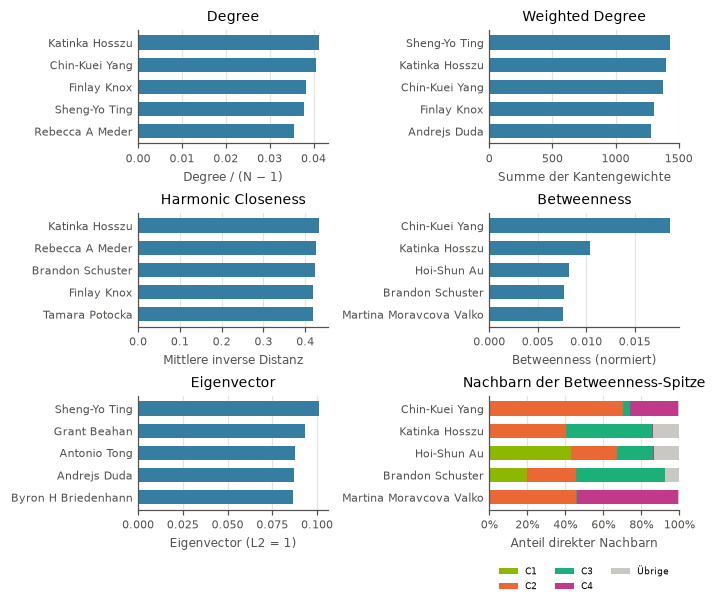

**Befund:** Katinka Hosszu hat den höchsten Degree (543 Nachbarn). Beim Weighted Degree führt Sheng-Yo Ting (1433); beim Eigenvector Sheng-Yo Ting. Diese Rollen müssen nicht zusammenfallen. Grosse Veranstaltungstage erzeugen in der Projektion dichte Nachbarschaften. Hohe Werte können deshalb auch die Abdeckung und Zusammensetzung der gespeicherten Bestleistungen widerspiegeln. Community-übergreifende Nachbarn belegen strukturelle Verbindungen; eine Vermittlungsrolle auf kürzesten Wegen benötigt zusätzlich Betweenness.

In [7]:
cols = 2
rows = int(np.ceil(len(available_metrics) / cols))
with plt.rc_context(REPORT_RC):
    fig, axes = plt.subplots(rows, cols, figsize=(6.3, 1.8 * rows), layout='constrained', squeeze=False)
    for ax, metric in zip(axes.flat, available_metrics):
        top = top_tables[metric].iloc[::-1]
        ax.barh(top['athlete_name'].map(pretty_name), top[metric], color=COLOR, height=.65)
        axis_labels = {'degree_centrality': 'Degree / (N − 1)',
                       'weighted_degree': 'Summe der Kantengewichte',
                       'harmonic': 'Mittlere inverse Distanz',
                       'eigenvector': 'Eigenvector (L2 = 1)',
                       'betweenness': 'Betweenness (normiert)'}
        ax.set(title=LABELS[metric], xlabel=axis_labels[metric])
        ax.tick_params(axis='y', length=0)
        ax.grid(axis='y', visible=False)
        ax.ticklabel_format(axis='x', style='plain', useOffset=False)
    for ax in list(axes.flat)[len(available_metrics):]:
        ax.set_visible(False)
    if len(available_metrics) == 5 and not betweenness_top.empty:
        ax = axes.flat[-1]
        ax.set_visible(True)
        shown = betweenness_top.head(5).iloc[::-1]
        left = np.zeros(len(shown))
        for community in [*COMMUNITY_COLORS, 'non_generation_neighbors']:
            values = shown[community].to_numpy(dtype=float) / shown['degree'].to_numpy(dtype=float)
            ax.barh(shown['athlete_name'].map(pretty_name), values, left=left, height=.65,
                    color=COMMUNITY_COLORS.get(community, '#c9c8c3'),
                    label=community if community in COMMUNITY_COLORS else 'Übrige')
            left += values
        ax.set(title='Nachbarn der Betweenness-Spitze', xlabel='Anteil direkter Nachbarn', xlim=(0, 1))
        ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
        ax.tick_params(axis='y', length=0)
        ax.grid(axis='y', visible=False)
        ax.legend(frameon=False, fontsize=6, ncol=3, loc='upper center', bbox_to_anchor=(.5, -.42))
    fig.savefig(REPORT_DIR / '06_zentralitaet_athleten.pdf', bbox_inches='tight')
    plt.show()

local_top = top_tables['degree_centrality'].iloc[0]
weighted_top = top_tables['weighted_degree'].iloc[0]
eigen_top = top_tables['eigenvector'].iloc[0]
display(Markdown(
    f"**Befund:** {pretty_name(local_top['athlete_name'])} hat den höchsten Degree "
    f"({int(actors.loc[top_tables['degree_centrality'].index[0], 'degree'])} Nachbarn). "
    f"Beim Weighted Degree führt {pretty_name(weighted_top['athlete_name'])} "
    f"({weighted_top['weighted_degree']:.0f}); beim Eigenvector "
    f"{pretty_name(eigen_top['athlete_name'])}. Diese Rollen müssen nicht zusammenfallen. "
    'Grosse Veranstaltungstage erzeugen in der Projektion dichte Nachbarschaften. '
    'Hohe Werte können deshalb auch die Abdeckung und Zusammensetzung der gespeicherten '
    'Bestleistungen widerspiegeln. Community-übergreifende Nachbarn belegen strukturelle '
    'Verbindungen; eine Vermittlungsrolle auf kürzesten Wegen benötigt zusätzlich Betweenness.'
))

## 6.4 Maximale FINA-Punkte und Zentralität

Wir bestimmen pro `athlete_id` den maximalen **verfügbaren** Punktewert aller
bereinigten Bestleistungseinträge. Fehlende Punkte werden nicht durch Null ersetzt.
Es gibt keine neue Umrechnung auf einheitliche jährliche FINA-Basistabellen.
Die Zahl gespeicherter Bestleistungen und der Einträge mit Punkten werden separat
ausgewiesen. Für alle Tests verwenden wir dieselben GC-Athleten mit Punkten und
allen aktuell verfügbaren Zentralitätsmassen; die ausgeschlossenen Athleten werden gezählt.

**Monadischer Permutationstest:** H0: Unter zufälliger Zuordnung der Punktewerte
zu den analysierten Athleten besteht kein positiver Zusammenhang mit Zentralität.
H1: Höhere Punkte gehen mit höherer Zentralität einher. Teststatistik und
Effektgrösse sind Spearmans $\rho$ (mittlere Ränge bei Bindungen). Netzwerk und
Zentralitäten bleiben fixiert; nur die Punktewerte bzw. ihre äquivalenten Ränge
werden über dieselben Athleten permutiert. Einseitiger Test mit $B=9'999$,
Seed 42 und $\alpha=0.05$; Monte-Carlo-$p=(1+\#\{\rho_b\geq\rho_{obs}\})/(B+1)$.
Die kleinste darstellbare Wahrscheinlichkeit ist 0.0001, niemals 0.
Zusätzlich korrigieren wir die verfügbaren Tests nach Holm; keine Unabhängigkeit
zwischen den verschiedenen Zentralitätsmassen wird vorausgesetzt.

Dies ist eine unstratifizierte Nullverteilung unter Austauschbarkeit der
Punktewerte, keine kausale Aussage und kein Nachweis, dass mögliche Unterschiede
zwischen Nationen oder Generationen kontrolliert sind. Unvollständige
Bestleistungsdaten können sowohl das Maximum als auch die Zentralität verringern.

In [8]:
clean_path = PROJECT_ROOT / 'data/processed/athlete_data_clean.parquet'
records = pd.read_parquet(clean_path, columns=['athlete_id', 'points'])
records['points'] = pd.to_numeric(records['points'], errors='coerce')
records.loc[~np.isfinite(records['points'].to_numpy(dtype=float, na_value=np.nan)), 'points'] = pd.NA
point_profile = records.groupby('athlete_id').agg(
    max_fina_points=('points', 'max'), n_records=('points', 'size'), n_point_records=('points', 'count')
)
actors = actors.join(point_profile, on='athlete_id', validate='one_to_one')
assert actors['n_records'].notna().all()
performance_population = actors.loc[gc_order].dropna(subset=['max_fina_points', *available_metrics])
assert np.isfinite(performance_population[['max_fina_points', *available_metrics]].to_numpy(dtype=float)).all()
display(pd.Series({
    'Athleten Arbeitsnetz': len(actors), 'Athleten GC': len(gc_order),
    'GC-Athleten ohne Punkte': int(actors.loc[gc_order, 'max_fina_points'].isna().sum()),
    'Gemeinsame Testpopulation': len(performance_population),
    'Nicht in der GC (nicht getestet)': int((~actors['in_gc']).sum()),
    'Median gespeicherte Bestleistungen (Testpopulation)': performance_population['n_records'].median(),
    'Spannweite Anzahl Bestleistungen (Minimum)': performance_population['n_records'].min(),
    'Spannweite Anzahl Bestleistungen (Maximum)': performance_population['n_records'].max(),
}, name='Anzahl').to_frame())

performance_tests = monadic_permutation_tests(
    performance_population, 'max_fina_points', available_metrics,
    n_permutations=N_PERMUTATIONS, seed=SEED, alpha=ALPHA,
)
display(performance_tests.round(5))
significant = performance_tests.index[performance_tests['reject_holm']].tolist()
display(Markdown(
    '**Testergebnis:** ' + ', '.join(
        f'{LABELS[m]}: ρ = {performance_tests.loc[m, "rho"]:.3f}, '
        f'p = {performance_tests.loc[m, "p"]:.4f}, '
        f'p (Holm) = {performance_tests.loc[m, "p_holm"]:.4f}' for m in available_metrics
    ) + f'. H0 wird nach Holm für {len(significant)} von {len(available_metrics)} Massen '
    'bei α = 0.05 verworfen. Die Effektgrössen werden getrennt von der Signifikanz '
    'beurteilt; es handelt sich um Zusammenhänge innerhalb dieser Datenauswahl.'
))
# Deskriptive Kontrolle der Datenabdeckung, kein zusätzlicher Signifikanztest.
coverage_correlations = performance_population[
    ['max_fina_points', 'n_records', *available_metrics]
].corr(method='spearman').loc[['max_fina_points', 'n_records']]
display(Markdown('**Deskriptive Spearman-Korrelationen mit der Zahl erfasster Bestleistungen:**'))
display(coverage_correlations.round(3))

,Anzahl
Athleten Arbeitsnetz,13156.0
Athleten GC,12709.0
GC-Athleten ohne Punkte,1.0
Gemeinsame Testpopulation,12708.0
Nicht in der GC (nicht getestet),447.0
Median gespeicherte Bestleistungen (Testpopulation),20.0
Spannweite Anzahl Bestleistungen (Minimum),2.0
Spannweite Anzahl Bestleistungen (Maximum),100.0


,rho,n,B,seed,p,p_holm,reject_holm,status
metric,,,,,,,,
degree_centrality,0.22874,12708,9999,42,0.0001,0.0005,True,ok
weighted_degree,0.16549,12708,9999,42,0.0001,0.0005,True,ok
harmonic,0.36045,12708,9999,42,0.0001,0.0005,True,ok
betweenness,0.32500,12708,9999,42,0.0001,0.0005,True,ok
eigenvector,0.29262,12708,9999,42,0.0001,0.0005,True,ok


**Testergebnis:** Degree: ρ = 0.229, p = 0.0001, p (Holm) = 0.0005, Weighted Degree: ρ = 0.165, p = 0.0001, p (Holm) = 0.0005, Harmonic Closeness: ρ = 0.360, p = 0.0001, p (Holm) = 0.0005, Betweenness: ρ = 0.325, p = 0.0001, p (Holm) = 0.0005, Eigenvector: ρ = 0.293, p = 0.0001, p (Holm) = 0.0005. H0 wird nach Holm für 5 von 5 Massen bei α = 0.05 verworfen. Die Effektgrössen werden getrennt von der Signifikanz beurteilt; es handelt sich um Zusammenhänge innerhalb dieser Datenauswahl.

**Deskriptive Spearman-Korrelationen mit der Zahl erfasster Bestleistungen:**

,max_fina_points,n_records,degree_centrality,weighted_degree,harmonic,betweenness,eigenvector
max_fina_points,1.000,0.273,0.229,0.165,0.360,0.325,0.293
n_records,0.273,1.000,0.383,0.491,0.326,0.377,0.177


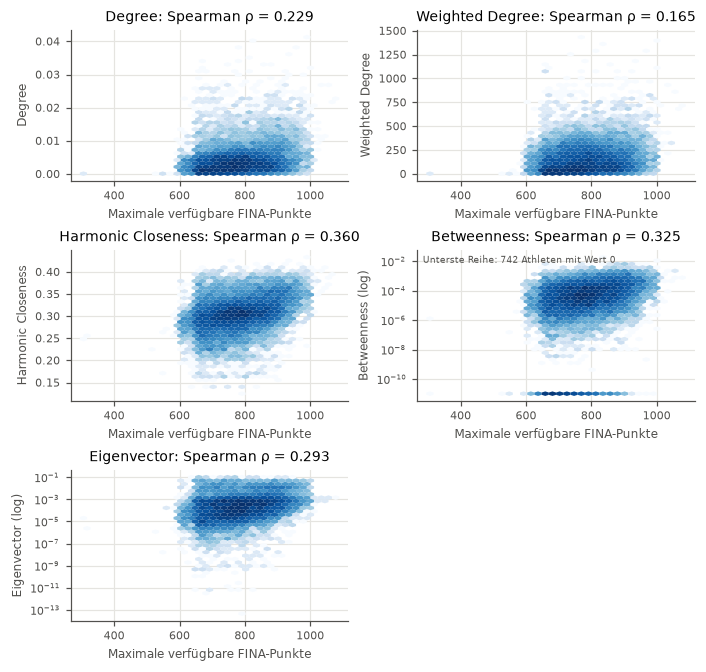

**Einordnung:** Die Tests beziehen sich auf 12,708 Athleten. Die Tabelle weist sowohl die Stärke des Zusammenhangs (ρ) als auch die Permutationsergebnisse aus; ein kleiner p-Wert allein beschreibt keine grosse Wirkung. TOP100-Auswahl, unterschiedliche Datenabdeckung und der Filter auf wiederholte gemeinsame Tage begrenzen die Verallgemeinerung. Insbesondere ersetzt die Zahl gespeicherter Bestleistungen keine vollständige Teilnahme- oder Karrierehistorie.

In [9]:
LOG_METRICS = {'betweenness', 'eigenvector'}
with plt.rc_context(REPORT_RC):
    rows = int(np.ceil(len(available_metrics) / 2))
    fig, axes = plt.subplots(rows, 2, figsize=(6.3, 2 * rows), layout='constrained', squeeze=False)
    for ax, metric in zip(axes.flat, available_metrics):
        x = performance_population['max_fina_points'].to_numpy(dtype=float)
        y = performance_population[metric].to_numpy(dtype=float)
        rho = spearmanr(x, y).statistic
        if metric in LOG_METRICS:
            # Stark schiefe Masse logarithmisch zeigen. Nullwerte liegen in der untersten Reihe.
            positive = y > 0
            floor = 10 ** np.floor(np.log10(y[positive].min()) - 1)
            y = np.where(positive, y, floor)
            ax.hexbin(x, y, gridsize=35, mincnt=1, bins='log', cmap='Blues',
                      linewidths=0, rasterized=True, yscale='log')
            if (~positive).any():
                ax.annotate(f'Unterste Reihe: {(~positive).sum()} Athleten mit Wert 0',
                            (0.02, 0.97), xycoords='axes fraction', va='top', fontsize=6,
                            color='#52514e')
            ylabel = f'{LABELS[metric]} (log)'
        else:
            ax.hexbin(x, y, gridsize=35, mincnt=1, bins='log', cmap='Blues', linewidths=0, rasterized=True)
            ax.ticklabel_format(axis='y', style='plain', useOffset=False)
            ylabel = LABELS[metric]
        ax.set(title=f'{LABELS[metric]}: Spearman ρ = {rho:.3f}',
               xlabel='Maximale verfügbare FINA-Punkte', ylabel=ylabel)
    for ax in list(axes.flat)[len(available_metrics):]:
        ax.set_visible(False)
    fig.savefig(REPORT_DIR / '06_zentralitaet_leistung.pdf', bbox_inches='tight')
    plt.show()

display(Markdown(
    f'**Einordnung:** Die Tests beziehen sich auf {len(performance_population):,} Athleten. '
    'Die Tabelle weist sowohl die Stärke des Zusammenhangs (ρ) als auch die '
    'Permutationsergebnisse aus; ein kleiner p-Wert allein beschreibt keine grosse Wirkung. '
    'TOP100-Auswahl, unterschiedliche Datenabdeckung und der Filter auf wiederholte '
    'gemeinsame Tage begrenzen die Verallgemeinerung. Insbesondere ersetzt die Zahl '
    'gespeicherter Bestleistungen keine vollständige Teilnahme- oder Karrierehistorie.'
))

## 6.5 Gruppen-Zentralität: Profilnationen und Generationen

Alle Gruppen werden auf **demselben vollständigen Arbeitsnetz** mit allen $N$
Knoten verglichen. Für eine Gruppe $S$ mit $|S|$ Mitgliedern gilt:

$$C_D(S)=\frac{|\{v\notin S:d(v,S)=1\}|}{N-|S|},\qquad
C_H(S)=\frac{1}{N-|S|}\sum_{v\notin S}\frac{1}{d(v,S)},\quad
d(v,S)=\min_{s\in S}d(v,s).$$

Unerreichbare Knoten tragen 0 bei, bleiben aber im Nenner. Gruppenmitglieder
selbst gehen nicht in den Durchschnitt ein. **Group Closeness ist hier der
Mittelwert inverser Distanzen**, nicht der inverse Mittelwert der Distanzen.
Eine ungewichtete Multi-Source-BFS startet gleichzeitig bei allen Mitgliedern,
findet für jeden übrigen Knoten die nächste Gruppe und benötigt pro Gruppe
$O(N+M)$ Zeit und $O(N)$ zusätzlichen Speicher.

Die Auswahl `>= 200` bezieht sich wie in Kapitel 4 auf Profilnationen unter
allen Athleten, nicht auf das Listenland und nicht auf die GC. C1–C4 stammen
unverändert aus Kapitel 5. Gruppengrösse, GC-Mitglieder, direkt und insgesamt
erreichte Aussenstehende werden gezeigt: Grössere Gruppen haben mehr mögliche
Ausgangspunkte, die Normierung beseitigt diesen Grösseneffekt nicht vollständig.
Group Betweenness wird wegen des Aufwands ausgelassen; gerichtete Prestige-Masse
werden auf diesem ungerichteten Netzwerk nicht zusätzlich verwendet.

In [10]:
nation_sizes = actors['athlete_nation'].value_counts()
profile_nations = nation_sizes[nation_sizes.ge(200)].sort_index()
print(f'{len(profile_nations)} Profilnationen mit mindestens 200 Athleten (alle Knoten).')
groups, group_status, _ = load_analysis_result(
    RESULT_DIR / 'group_centralities.parquet', work_metadata,
    community_sha256=community_sha256,
    required_columns=['type', 'gc_members', 'size', 'outside', 'reached_direct',
                      'reached_any', 'group_degree', 'group_closeness'],
)
expected_group_names = set(profile_nations.index) | (set(COMMUNITY_COLORS) if community_sha256 else set())
if groups is not None and set(groups.index) != expected_group_names:
    groups = None
    group_status = {'status': 'invalid', 'reason': 'Gruppenauswahl stimmt nicht überein.'}
groups_reused = groups is not None
if not groups_reused:
    group_rows = []
    for nation in profile_nations.index:
        members = actors.index[actors['athlete_nation'].eq(nation)]
        group_rows.append({'group': nation, 'type': 'Profilnation',
                           'gc_members': int(actors.loc[members, 'in_gc'].sum()),
                           **group_centrality(G_work, members)})
    if community_sha256 is not None:
        for label in COMMUNITY_COLORS:
            members = actors.index[actors['community'].eq(label)]
            group_rows.append({'group': label, 'type': 'Generation',
                               'gc_members': int(actors.loc[members, 'in_gc'].sum()),
                               **group_centrality(G_work, members)})
    groups = pd.DataFrame(group_rows).set_index('group')
    group_status = {'status': 'computed', 'reason': 'Kein gültiger Gruppenexport.'}
print('Gruppen-Zentralität:', group_status)
assert groups['group_degree'].between(0, 1).all()
assert groups['group_closeness'].between(groups['group_degree'], 1).all()
display(groups.sort_values(['type', 'group_degree'], ascending=[True, False]).round(4))

22 Profilnationen mit mindestens 200 Athleten (alle Knoten).
Gruppen-Zentralität: {'status': 'loaded', 'reason': 'Validated saved analysis result loaded.'}


,type,gc_members,size,outside,reached_direct,reached_any,group_degree,group_closeness
group,,,,,,,,
C3,Generation,1304,1304,11852,4876,11405,0.4114,0.6733
C1,Generation,2064,2064,11092,4294,10645,0.3871,0.6512
C2,Generation,1881,1881,11275,3923,10828,0.3479,0.6365
C4,Generation,1175,1175,11981,1240,11534,0.1035,0.4548
United States,Profilnation,203,206,12950,2905,12506,0.2243,0.5815
Japan,Profilnation,197,200,12956,2817,12512,0.2174,0.5753
Hong Kong,Profilnation,188,200,12956,2775,12522,0.2142,0.5756
China,Profilnation,195,201,12955,2774,12514,0.2141,0.5762
Great Britain,Profilnation,205,208,12948,2746,12504,0.2121,0.5774


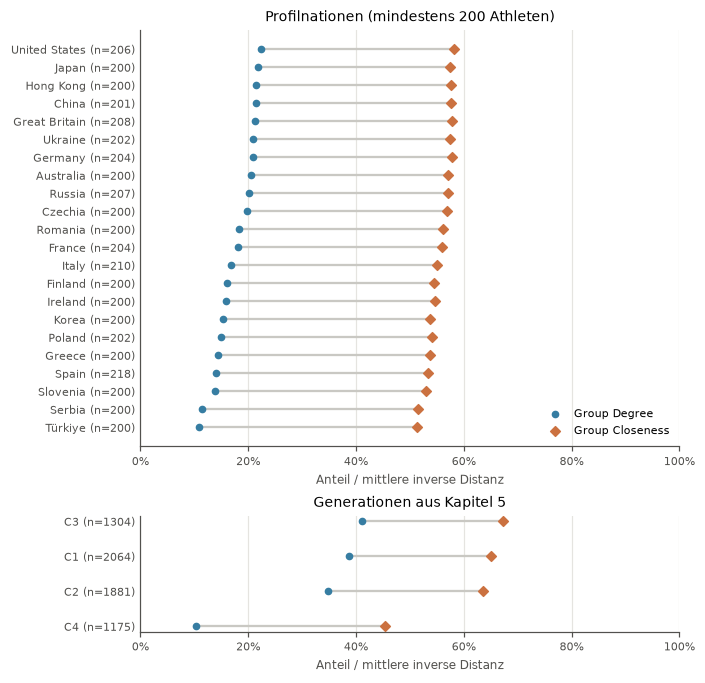

**Befund:** Unter den 22 Profilnationen erreicht United States (206 Mitglieder) mit Group Degree 22.4% den grössten Anteil direkter Nachbarn ausserhalb der Gruppe. Die Graphbasis und der Umgang mit unerreichbaren Knoten sind für Nationen und Generationen gleich. C1–C4 sind wesentlich grösser als die einzelnen Profilnationen; ihre Reichweite darf deshalb nicht als grössenbereinigte Überlegenheit interpretiert werden.

**Generationen:** C3 erreicht mit 41.1% direkten Aussenkontakten und 0.673 Group Closeness die höchsten Werte der vier Gruppen, obwohl C1 mehr Mitglieder besitzt. C4 liegt bei 10.3% bzw. 0.455. Die zeitliche Struktur aus Kapitel 5 geht somit mit unterschiedlicher Reichweite im beobachteten Gesamtnetz einher. Gruppengrösse, Lage und Datenabdeckung bleiben dabei miteinander verbunden; der Vergleich isoliert keine Ursache.

In [11]:
with plt.rc_context(REPORT_RC):
    nation_groups = groups[groups['type'].eq('Profilnation')].sort_values('group_degree')
    generation_groups = groups[groups['type'].eq('Generation')].sort_values('group_degree')
    panels = 2 if len(generation_groups) else 1
    fig, axes = plt.subplots(panels, 1, figsize=(6.3, 6.1 if panels == 2 else 4.8),
                              layout='constrained', squeeze=False,
                              gridspec_kw={'height_ratios': [4.5, 1.25]} if panels == 2 else {})
    for ax, frame, title in zip(axes.flat, [nation_groups, generation_groups],
                                ['Profilnationen (mindestens 200 Athleten)', 'Generationen aus Kapitel 5']):
        y = np.arange(len(frame))
        ax.hlines(y, frame['group_degree'], frame['group_closeness'], color='#c9c8c3')
        ax.scatter(frame['group_degree'], y, s=16, color=COLOR, label='Group Degree', zorder=3)
        ax.scatter(frame['group_closeness'], y, s=20, color='#cb7140', marker='D',
                   label='Group Closeness', zorder=3)
        ax.set(yticks=y, yticklabels=[f'{g} (n={int(frame.loc[g, "size"])})' for g in frame.index],
               title=title, xlim=(0, 1), xlabel='Anteil / mittlere inverse Distanz')
        ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
        ax.tick_params(axis='y', length=0)
        ax.grid(axis='y', visible=False)
    axes.flat[0].legend(frameon=False, loc='lower right', fontsize=7)
    if not groups_reused or not (REPORT_DIR / '06_zentralitaet_gruppen.pdf').exists():
        fig.savefig(REPORT_DIR / '06_zentralitaet_gruppen.pdf', bbox_inches='tight')
    plt.show()

best_nation = nation_groups['group_degree'].idxmax()
display(Markdown(
    f'**Befund:** Unter den {len(profile_nations)} Profilnationen erreicht {best_nation} '
    f'({int(nation_groups.loc[best_nation, "size"])} Mitglieder) mit Group Degree '
    f'{nation_groups.loc[best_nation, "group_degree"]:.1%} den grössten Anteil '
    'direkter Nachbarn ausserhalb der Gruppe. Die Graphbasis und der Umgang mit '
    'unerreichbaren Knoten sind für Nationen und Generationen gleich. C1–C4 sind '
    'wesentlich grösser als die einzelnen Profilnationen; ihre Reichweite darf '
    'deshalb nicht als grössenbereinigte Überlegenheit interpretiert werden.'
))
if len(generation_groups):
    display(Markdown(
        '**Generationen:** C3 erreicht mit '
        f'{generation_groups.loc["C3", "group_degree"]:.1%} direkten Aussenkontakten '
        f'und {generation_groups.loc["C3", "group_closeness"]:.3f} Group Closeness die '
        'höchsten Werte der vier Gruppen, obwohl C1 mehr Mitglieder besitzt. C4 liegt '
        f'bei {generation_groups.loc["C4", "group_degree"]:.1%} bzw. '
        f'{generation_groups.loc["C4", "group_closeness"]:.3f}. Die zeitliche Struktur '
        'aus Kapitel 5 geht somit mit unterschiedlicher Reichweite im beobachteten '
        'Gesamtnetz einher. Gruppengrösse, Lage und Datenabdeckung bleiben dabei '
        'miteinander verbunden; der Vergleich isoliert keine Ursache.'
    ))

### Gruppen-Zentralität und nationale Vernetzung

In Kapitel 4 haben wir pro Nation den Anteil gemeinsamer Tage mit Landsleuten bestimmt. Hier prüfen wir, ob Nationalteams mit hohem nationalem Anteil weniger Aussenstehende erreichen (Spearman über die 22 Nationen).

In [12]:
nations_graph = nx.read_gexf(NETWORK_DIR / 'nations.gexf')
internal = pd.Series(nx.get_node_attributes(nations_graph, 'internal_weight')).astype(float)
external = pd.Series(dict(nations_graph.degree(weight='weight'))).astype(float)
# Wie in Kapitel 4: Eine Kante zwischen Landsleuten zählt für beide Athleten.
national_share = 2 * internal / (2 * internal + external)

nation_comparison = groups[groups['type'].eq('Profilnation')][['group_degree', 'group_closeness']].assign(
    national_share=national_share
)
assert nation_comparison['national_share'].notna().all()
rho_share = nation_comparison.corr(method='spearman')
display(rho_share.round(2))
display(nation_comparison.sort_values('national_share').round(3))

,group_degree,group_closeness,national_share
group_degree,1.00,0.97,-0.82
group_closeness,0.97,1.00,-0.77
national_share,-0.82,-0.77,1.00


,group_degree,group_closeness,national_share
group,,,
United States,0.224,0.581,0.208
Hong Kong,0.214,0.576,0.211
Korea,0.154,0.537,0.228
Japan,0.217,0.575,0.248
China,0.214,0.576,0.267
Great Britain,0.212,0.577,0.348
Ukraine,0.209,0.575,0.424
Germany,0.209,0.578,0.491
Australia,0.206,0.571,0.505


## 6.6 Ergebnisse sichern und Vollständigkeit prüfen

Die Auswertung speichert Tabellen als Parquet mit eingebetteten JSON-Metadaten.
`analysis_metadata.json` hält Eingabefingerprints, Definitionen, Testeinstellungen,
Graphgrössen und den Status der teuren Masse lesbar fest. Die Caches enthalten
zusätzliche methodenspezifische Metadaten und werden beim erneuten Start geprüft.
Die drei PDF-Abbildungen liegen wie in den vorigen Kapiteln in `Report/graphics/`.

Der abschliessende Standardlauf liest Harmonic und exakte Betweenness aus ihren
gültigen Caches sowie die unveränderten Basismasse und Gruppenwerte aus den
Ergebnisexporten. Alle fünf Aktormasse, ihre Rangkorrelationen, die fünf
FINA-Tests und die Community-Nachbarn der Betweenness-Spitze sind damit enthalten.
Die Tabelle am Ende prüft den tatsächlichen Status; bei später fehlenden oder
ungültigen Caches bleibt das betreffende Mass weiterhin sichtbar offen.
Der Report wird nicht automatisch überschrieben.

Methodenreferenzen: [NetworkX Betweenness](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.centrality.betweenness_centrality.html),
[NetworkX Harmonic Centrality](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.centrality.harmonic_centrality.html)
und [SciPy shortest_path](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.csgraph.shortest_path.html).
Die Formeln folgen den im Auftrag genannten SAN-Definitionen; ein separates
SAN-Skript liegt im Repository nicht vor.

In [13]:
analysis_metadata = {
    'schema_version': 1, 'graph': graph_metadata(G_work, source_sha256, WORK_THRESHOLD, population='all_nodes'),
    'giant_component': gc_metadata, 'community_sha256': community_sha256,
    'clean_data_sha256': digest(clean_path), 'graph_summary': graph_summary,
    'available_metrics': available_metrics, 'expensive_status': cache_status,
    'base_measures_status': base_status, 'group_measures_status': group_status,
    'normalizations': {'degree_centrality': 'degree/(N_all-1)',
                       'weighted_degree': 'sum of retained edge weights; no normalization',
                       'harmonic': 'sum(1/d)/(n_gc-1); unweighted',
                       'betweenness': 'unordered-pair sum / choose(n_gc-1,2); no endpoints; unweighted',
                       'eigenvector': 'GC unweighted adjacency; L2=1; scipy eigsh LA tol=1e-10',
                       'group_degree': 'direct outside neighbors/(N_all-|S|)',
                       'group_closeness': 'sum_outside(1/min_distance)/(N_all-|S|); unreachable=0'},
    'permutation': {'B': N_PERMUTATIONS, 'seed': SEED, 'alpha': ALPHA,
                    'alternative': 'greater', 'statistic_and_effect': 'Spearman rho',
                    'p_correction': '(exceedances+1)/(B+1)', 'multiplicity': 'Holm',
                    'population': 'GC, complete cases across available metrics and maximum points',
                    'n': len(performance_population)},
    'profile_nations_minimum': 200, 'profile_nations_count': len(profile_nations),
    'group_population': 'all_nodes', 'eigenvector_residual': float(eigen_residual),
}

def save_result(frame, filename):
    table = pa.Table.from_pandas(frame, preserve_index=True)
    metadata = dict(table.schema.metadata or {})
    metadata[b'athletes_network_analysis'] = json.dumps(analysis_metadata, ensure_ascii=False).encode('utf-8')
    pq.write_table(table.replace_schema_metadata(metadata), RESULT_DIR / filename)

save_result(actors, 'actor_centralities.parquet')
save_result(rank_correlations, 'rank_correlations.parquet')
save_result(performance_tests, 'performance_tests.parquet')
save_result(groups, 'group_centralities.parquet')
save_result(examples, 'example_athletes.parquet')
if not neighbor_profiles.empty:
    save_result(neighbor_profiles, 'neighbor_communities.parquet')
if not betweenness_top.empty:
    save_result(betweenness_top, 'betweenness_bridges.parquet')
(RESULT_DIR / 'analysis_metadata.json').write_text(
    json.dumps(analysis_metadata, ensure_ascii=False, indent=2), encoding='utf-8'
)
completed = pd.DataFrame([
    {'Analyse': LABELS[m], 'Status': 'berechnet / gültiger Cache' if m in available_metrics
      else 'OFFEN – Cache fehlt oder ungültig'} for m in metric_order
] + [
    {'Analyse': 'Leistung: Spearman und monadische Permutationen', 'Status': f'{len(available_metrics)} verfügbare Masse'},
    {'Analyse': 'Gruppen-Zentralität', 'Status': f'{len(profile_nations)} Nationen, {len(generation_groups)} Generationen'},
    {'Analyse': 'Betweenness-Spitze und Generationen', 'Status': 'ausgewertet' if 'betweenness' in available_metrics else 'OFFEN'},
])
display(completed)
print('Ergebnisse:', RESULT_DIR.relative_to(PROJECT_ROOT))

,Analyse,Status
0,Degree,berechnet / gültiger Cache
1,Weighted Degree,berechnet / gültiger Cache
2,Harmonic Closeness,berechnet / gültiger Cache
3,Betweenness,berechnet / gültiger Cache
4,Eigenvector,berechnet / gültiger Cache
5,Leistung: Spearman und monadische Permutationen,5 verfügbare Masse
6,Gruppen-Zentralität,"22 Nationen, 4 Generationen"
7,Betweenness-Spitze und Generationen,ausgewertet


Ergebnisse: data/processed/centrality
